# PROJET BIG DATA - Natural Language Processing with Disaster Tweets

## Carnet d'exploration : hypotheses, essais et evaluation

Projet universitaire de M2, Universite de Lille. Le titre Big Data designe le
cours : ce travail utilise un corpus local et ne revendique pas de calcul distribue.

Le notebook presente la demarche : inspection des tweets, liens, hashtags,
construction de variables, lexiques, pistes geographiques, visualisations,
comparaison de modeles et evaluation. Les pistes non retenues restent visibles
en commentaire, avec leurs raisons et leurs limites.

**Organisation** : le holdout est reserve des le chargement, avant les
graphiques et les statistiques exploratoires. L'exploration porte uniquement
sur le sous-ensemble d'entrainement ; le holdout est utilise pour l'evaluation
finale du modele choisi par validation croisee. La separation et la pipeline
sont partagees avec le CLI pour garantir la coherence des executions.

**Lecture des statuts** : *exploratoire* = hypothese decrite et observee ;
*non retenue* = piste documentee, non utilisee dans le modele final ;
*retenue* = variable utilisee, sans preuve d'apport individuel par ablation.

**Limites de l'evaluation** : une separation interne ne remplace pas un corpus
independant. Ce corpus ayant deja ete explore, deplacer la separation ne rend
pas les choix de variables passes independants des donnees d'evaluation.
La generalisation a de nouveaux evenements reste a verifier.

### Importation des librairies et configuration de l'affichage 

In [1]:
from pathlib import Path
import json
import platform
import re

import pandas as pd
from geosky import geo_plug
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from pandas.testing import assert_frame_equal
from sklearn.calibration import CalibrationDisplay
from sklearn.metrics import ConfusionMatrixDisplay

from projet_nlp.src.config import COLS_NUMERIQUES
from projet_nlp.src.feature_engineering import (
    appliquer_feature_engineering,
    remove_source_prefix as nettoyer_source_partage,
)
from projet_nlp.src.training import entrainer, groupes_depuis_textes_bruts, creer_partitions

# Piste non retenue : warnings.filterwarnings('ignore')
# Masquer les avertissements cacherait notamment les problemes de fit.
pd.set_option("display.max_colwidth", 200)

[Info] Loading Data


[Info] Loading Data completed


Les bibliotheques servent a manipuler les donnees, visualiser les distributions
et tester les transformations. Les imports du package relient explicitement
l'exploration a la pipeline finale. Les avertissements restent visibles.

In [2]:
print("Version Python :", platform.python_version())
print("Repertoire de travail :", Path.cwd().name)
# Piste non retenue : print(sys.executable)
# Utile en local, mais on evite de publier le chemin personnel de l'interpreteur.

Version Python : 3.12.10
Repertoire de travail : disaster-tweets-nlp-portfolio


Verification de l'environnement sans enregistrer de chemin utilisateur dans les
sorties. Executer depuis la racine du depot, avec les dependances du README.

## Variables

In [3]:
# Piste non retenue : tester jour/mois AVANT jour/mois/annee.
# "10/07/2015" etait donc compte comme "10/07" puis "2015".
# Les formes les plus longues doivent etre essayees en premier.
MOIS = (
    r"January|February|March|April|May|June|July|August|"
    r"September|October|November|December"
)
date_pattern = rf"""
(?<!\w)(?:
    \d{{1,2}}[/-]\d{{1,2}}[/-](?:19|20)\d{{2}}
    | \d{{1,2}}\s+(?:{MOIS})\s+(?:19|20)\d{{2}}
    | (?:{MOIS})\s+(?:19|20)\d{{2}}
    | \d{{1,2}}[/-](?:19|20)\d{{2}}
    | \d{{1,2}}\s+(?:{MOIS})
    | \d{{1,2}}[/-]\d{{1,2}}
    | (?:19|20)\d{{2}}
)(?!\w)
"""
for exemple in ["10/07/2015", "10 July 2015", "July 2015", "2015"]:
    assert len(re.findall(date_pattern, exemple, flags=re.I | re.X)) == 1

**Hypothese exploratoire** : une date pourrait signaler un recit factuel.
Le motif reconnait plusieurs formes et compte une date complete une seule fois.
Il reste heuristique : `99/99/2015` ressemble a une date pour la regex, sans etre
une date valide. Ce n'est pas un parseur de calendrier. Les variables de dates
ne sont pas retenues dans le modele final.

In [4]:
us_states = [
    "alabama","alaska","arizona","arkansas","california","colorado",
    "connecticut","delaware","florida","georgia","hawaii","idaho",
    "illinois","indiana","iowa","kansas","kentucky","louisiana",
    "maine","maryland","massachusetts","michigan","minnesota",
    "mississippi","missouri","montana","nebraska","nevada",
    "new hampshire","new jersey","new mexico","new york",
    "north carolina","north dakota","ohio","oklahoma","oregon",
    "pennsylvania","rhode island","south carolina","south dakota",
    "tennessee","texas","utah","vermont","virginia","washington",
    "west virginia","wisconsin","wyoming"
]

Liste des noms des 50 états américains (en minuscules) utilisée pour la détection de lieux dans les tweets.

Le dictionnaire de villes ci-dessous est une piste geographique, pas un lexique
exhaustif. Son contenu a ete propose pendant l'exploration du corpus.

In [5]:
city_to_country_continent = {
    "la ronge": ("canada", "north america"),
    "tampa": ("united states", "north america"),
    "colorado springs": ("united states", "north america"),
    "ruby": ("united states", "north america"),
    "manitou": ("united states", "north america")
}

Petit dictionnaire de villes mappées vers leur pays et continent. Ce dictionnaire personnalisée sert d'exemple pour la détection de villes dans les tweets.

In [6]:
country_to_continent = {
    "united states": "north america",
    "canada": "north america",
    "mexico": "north america",

    "france": "europe",
    "germany": "europe",
    "italy": "europe",
    "spain": "europe",
    "united kingdom": "europe",

    "japan": "asia",
    "china": "asia",
    "india": "asia",

    "brazil": "south america",
    "argentina": "south america",

    "nigeria": "africa",
    "south africa": "africa",

    "australia": "oceania"
}

**Piste non retenue** : rattacher un pays a un continent. Ce dictionnaire est
partiel ; le conserver documente l'idee, mais aucune variable continent
n'est effectivement utilisee dans le modele final.

In [7]:
source_keywords = [
    "dtn",
    "reuters",
    "cnn",
    "bbc",
    "afp",
    "ap",
    "news"
]

Liste de mots associés à des sources d'information (presse) pouvant apparaître en préfixe d'un tweet (ex. "CNN: ...").

In [8]:
catastrophe_words = {
    "fire",
    "storm",
    "earthquake",
    "flood",
    "hurricane",
    "tsunami",
    "volcano",
    "tornado",
    "drought",
    "wildfire",
    "avalanche",
    "landslide",
    "blizzard",
    "sinkhole",
    "famine",
    "epidemic",
    "pandemic",
    "chemical spill",
    "radiation leak",
    "nuclear disaster",
    "incendie",
    "tempete",
    "terremblement de terre",
    "inondation",
    "ouragan",
    "tsunami",
    "volcan",
    "tornade",
    "secheresse",
    "feu de forêt",
    "avalanche",
    "glissement de terrain",
    "blizzard",
    "fissure du sol",
    "famine",
    "epidemie",
    "pandémie",
    "deversement chimique",
    "fuite de radiations",
    "catastrophe nucléaire"
}

Ensemble de mots et termes (anglais et français) décrivant divers types de catastrophes — utilisé pour marquer ou extraire la présence d'un terme catastrophe dans un tweet.

### Importation des tables

In [9]:
DATA_DIR = Path("projet_nlp") / "data"
# Lecture stricte : ne pas supprimer silencieusement les lignes CSV mal formees.
df_test_brut = pd.read_csv(DATA_DIR / "test.csv")
df_train_brut = pd.read_csv(DATA_DIR / "train.csv")
for nom, donnees in [("train", df_train_brut), ("test", df_test_brut)]:
    assert {"id", "text"}.issubset(donnees.columns), f"Colonnes absentes : {nom}"
    assert donnees["id"].notna().all() and donnees["id"].is_unique
    assert donnees["text"].map(lambda text: isinstance(text, str) and bool(text.strip())).all()
assert df_train_brut["target"].isin([0, 1]).all()
assert df_train_brut["target"].nunique() == 2
assert "target" not in df_test_brut

# Les regles de normalisation des groupes sont fixes, sans ajustement au corpus.
# Un train_test_split ordinaire peut repartir les copies d'un tweet des deux cotes.
groupes_evaluation = groupes_depuis_textes_bruts(df_train_brut["text"])
indices_fit, indices_holdout, plis_cv = creer_partitions(
    df_train_brut, df_train_brut["target"], groupes_evaluation,
)
assert not set(groupes_evaluation.iloc[indices_fit]) & set(groupes_evaluation.iloc[indices_holdout])

df_exploration_brut = df_train_brut.iloc[indices_fit].copy()
ids_holdout_reserves = frozenset(df_train_brut.iloc[indices_holdout]["id"])
df_train = df_exploration_brut.copy()
df_test = df_test_brut.copy()
assert not set(df_train["id"]) & ids_holdout_reserves
display(pd.Series({
    "entrainement_et_exploration": len(indices_fit),
    "holdout_reserve": len(indices_holdout),
    "test_Kaggle_sans_cible": len(df_test),
}, name="effectifs").to_frame())

,effectifs
entrainement_et_exploration,6090
holdout_reserve,1523
test_Kaggle_sans_cible,3263


### Reserver l'evaluation avant l'exploration

Le premier pli d'un `StratifiedGroupKFold` a cinq plis, graine 42, reserve
environ 20 % des observations. La stratification utilise les etiquettes pour
approcher la repartition des classes ; le regroupement empeche les copies de
textes normalises de traverser la separation. Les proportions ne sont pas
necessairement exactes, car un groupe reste indivisible.

`df_train` et `df_exploration_brut` contiennent uniquement les lignes
d'entrainement. Les apercus, graphiques, quantiles, modalites rares et correlations
qui suivent portent sur ces lignes, **pas sur le holdout**. `df_train_brut`
conserve le CSV complet pour l'appel au protocole partage et le reajustement
final, mais n'est pas le tableau d'exploration.

Les regles de normalisation des groupes ne sont pas apprises : ce ne sont ni
un TF-IDF ni des seuils estimes sur le holdout. Les doublons normalises sont
groupes, pas tous les quasi-doublons ou tweets du meme evenement.
`df_test` est le test Kaggle sans cible ; ce n'est pas notre holdout etiquete.

In [10]:
df_test.head()

,id,keyword,location,text
0,0,NaN,NaN,Just happened a terrible car crash
1,2,NaN,NaN,"Heard about #earthquake is different cities, stay safe everyone."
2,3,NaN,NaN,"there is a forest fire at spot pond, geese are fleeing across the street, I cannot save them all"
3,9,NaN,NaN,Apocalypse lighting. #Spokane #wildfires
4,11,NaN,NaN,Typhoon Soudelor kills 28 in China and Taiwan


Affichage des premières lignes du jeu de test pour vérification visuelle du format et des colonnes.

In [11]:
df_train.head(20)

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1
5,8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,1
6,10,NaN,NaN,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",1
7,13,NaN,NaN,I'm on top of the hill and I can see a fire in the woods...,1
8,14,NaN,NaN,There's an emergency evacuation happening now in the building across the street,1
10,16,NaN,NaN,Three people died from the heat wave so far,1


Apercu des 20 premieres lignes du sous-ensemble d'entrainement.
Les lignes du holdout ne sont pas inspectees pendant l'exploration.

In [12]:
df_train = df_train[["id", "keyword", "location", "text", "target"]].copy()
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


Sélection des colonnes d'intérêt (id, keyword, location, text, target) dans le DataFrame d'entraînement puis affichage d'un aperçu.

### Trouver les lignes qui contiennent un lien HTTPS

In [13]:
df_train_filter_https = df_train[df_train["text"].str.contains("https://", regex=False, na=False)].copy()

Filtrage des tweets contenant la chaîne 'https://' afin d'isoler les tweets qui incluent des liens externes sécurisés.

In [14]:
df_train_filter_https.head()

,id,keyword,location,text,target
57,81,ablaze,"Sao Paulo, Brazil",Set our hearts ablaze and every city was a gift And every skyline was like a kiss upon the lips @Û_ https://t.co/cYoMPZ1A0Z,0
62,89,ablaze,Twitter Lockout in progress,Rene Ablaze &amp; Jacinta - Secret 2k13 (Fallen Skies Edit) - Mar 30 2013 https://t.co/7MLMsUzV1Z,0
68,97,accident,"Nashville, TN",Accident on I-24 W #NashvilleTraffic. Traffic moving 8m slower than usual. https://t.co/0GHk693EgJ,1
76,110,accident,Norf Carolina,'By accident' they knew what was gon happen https://t.co/Ysxun5vCeh,0
94,136,accident,Alberta | Sask. | Montana,Suffield Alberta Accident https://t.co/bPTmlF4P10,1


Affiche un aperçu des tweets contenant des liens 'https://'.

In [15]:
df_train_filter_https = df_train_filter_https.copy()
df_train = df_train.copy()

Création de copies explicites des DataFrames filtrés — utile pour éviter les avertissements liés à l'affectation sur une vue pandas.

### Affichage du nombre des lignes avec et sans https

In [16]:
print(df_train.shape[0])
print(df_train_filter_https.shape[0])

6090
316


On mesure ici la frequence des liens HTTPS, pas leur pouvoir predictif.
Une difference de frequence entre classes pourrait inspirer une hypothese,
mais ne suffit pas a prouver qu'une variable ameliore le modele.

### Le nombre de tweet avec des hashtags

In [17]:
df_train_filter_hastag = df_train[df_train['text'].str.contains('#', na=False)]
df_train_filter_hastag.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1
5,8,NaN,NaN,#RockyFire Update => California Hwy. 20 closed in both directions due to Lake County fire - #CAfire #wildfires,1
6,10,NaN,NaN,"#flood #disaster Heavy rain causes flash flooding of streets in Manitou, Colorado Springs areas",1


Filtrage des tweets contenant au moins un caractère '#' pour analyser l'utilisation des hashtags.

In [18]:
print(df_train_filter_hastag.shape[0])

1411


Affiche le nombre de tweets contenant des hashtags.

### Compter le nombre de tweet avec catastrophe

In [19]:
df_train_filter_target = df_train[df_train['target'] == 1]

Sélection des tweets étiquetés comme relatant une catastrophe (colonne target égale à 1).

In [20]:
print(df_train_filter_target.shape[0])

2617


Effectif de la classe catastrophe. Cette inspection motive une stratification et
le suivi du F1 de la classe positive, pas seulement de l'accuracy. Une reference
qui repond toujours « non-catastrophe » peut deja avoir une accuracy assez elevee.

### Extraire les noms des locations du monde

In [21]:
# Exploration de l'API geosky ; les pays suffisent aux essais executes ensuite.
geo_plug.all_CountryNames()[:10]

# Pistes d'exploration de l'API, non executees :
# geo_plug.all_Country_StateNames()
# geo_plug.all_State_CityNames('Odisha')
# Ces appels exposent l'API, mais leurs resultats ne sont pas utilises ici.
# Source : https://stackoverflow.com/a
# Posted by Jyotiprakash panigrahi, retrieved 2026-01-26, CC BY-SA 4.0.
# Le lien incomplet ne permet pas d'identifier precisement la reponse.

['Andorra',
 'United Arab Emirates',
 'Afghanistan',
 'Antigua and Barbuda',
 'Anguilla',
 'Albania',
 'Armenia',
 'Angola',
 'Argentina',
 'American Samoa']

Utilisation de la bibliothèque geosky/geo_plug pour récupérer des listes de noms géographiques: pays, états et villes par état. Ces listes sont utiles pour la détection de lieux dans le texte.

In [22]:
all_countries = pd.DataFrame(geo_plug.all_CountryNames())


Construction d'un DataFrame contenant la liste des pays retournés par geo_plug pour inspection.

In [23]:
all_countries.head()

,0
0,Andorra
1,United Arab Emirates
2,Afghanistan
3,Antigua and Barbuda
4,Anguilla


Affiche un aperçu des pays extraits.

### Réduire les noms en minuscule des tweets et des locations du monde extraite

In [24]:
all_countries[0] = all_countries[0].str.lower()
all_countries.head()

,0
0,andorra
1,united arab emirates
2,afghanistan
3,antigua and barbuda
4,anguilla


Les noms de pays sont maintenant affectes en minuscules. Une expression
sans affectation affiche une serie transformee sans modifier `all_countries`.

In [25]:
df_train.head()

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1


Vérification d'un aperçu du DataFrame d'entraînement après les premières transformations.

In [26]:
df_train["text"].str.lower().head()

0                                                                    our deeds are the reason of this #earthquake may allah forgive us all
1                                                                                                   forest fire near la ronge sask. canada
2    all residents asked to 'shelter in place' are being notified by officers. no other evacuation or shelter in place orders are expected
3                                                                        13,000 people receive #wildfires evacuation orders in california 
4                                                 just got sent this photo from ruby #alaska as smoke from #wildfires pours into a school 
Name: text, dtype: str

**Apercu uniquement** : cette expression ne modifie pas `df_train`.
Nous gardons le texte brut pour compter caracteres, chiffres et ponctuation.
La normalisation du texte destine au modele sera appliquee explicitement
dans la pipeline partagee, apres ces comptages.

## Fonction création variables binaires 

### Comment lire les variables construites ci-dessous ?

Nous essayons des comptages et des indicatrices pour decrire les tweets.
Le regroupement des modalites rares selon leur frequence est **exploratoire** :
il est calcule sur le tableau observe, et ne constitue pas une transformation
d'inference stable si on le recalcule sur chaque lot. Pour une utilisation en
modele, il faudrait apprendre ces regroupements dans chaque pli d'entrainement.
La pipeline finale n'utilise pas ces regroupements ; elle retient des comptages
et des indicatrices a definition fixe.

In [27]:
def variable_exacte_hashtag(df, texte_colonne, seuil=10):
    df['nb_hashtag'] = df[texte_colonne].astype(str).str.count("#")
    valeurs_uniques = sorted(df['nb_hashtag'].unique())
    col_groupe = []
    for val in valeurs_uniques:
        nom_col = f"contient_{val}_hashtag"
        df[nom_col] = (df['nb_hashtag'] == val).astype(int)
        pourcentage = df[nom_col].mean() * 100
        if pourcentage >= seuil:
            print(f"{nom_col} : {pourcentage:.2f}% → gardée")
        else:
            print(f"{nom_col} : {pourcentage:.2f}% → regroupée")
            col_groupe.append(val)
    if col_groupe:
        nom_regroupement = "contient_" + "_".join(map(str, col_groupe)) + "_hashtags"
        df[nom_regroupement] = df['nb_hashtag'].isin(col_groupe).astype(int)
        for val in col_groupe:
            df.drop(columns=f"contient_{val}_hashtag", inplace=True)
    return df
variable_exacte_hashtag(df_train, 'text')

contient_0_hashtag : 76.83% → gardée
contient_1_hashtag : 12.78% → gardée
contient_2_hashtag : 5.27% → regroupée
contient_3_hashtag : 2.73% → regroupée
contient_4_hashtag : 1.03% → regroupée
contient_5_hashtag : 0.59% → regroupée
contient_6_hashtag : 0.31% → regroupée
contient_7_hashtag : 0.11% → regroupée
contient_8_hashtag : 0.11% → regroupée
contient_9_hashtag : 0.03% → regroupée
contient_10_hashtag : 0.15% → regroupée
contient_11_hashtag : 0.02% → regroupée
contient_13_hashtag : 0.03% → regroupée


,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1
...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0


Fonction qui compte le nombre de hashtags par tweet et crée des variables binaires indiquant si un tweet contient exactement N hashtags. Les catégories peu fréquentes sont regroupées selon un seuil en pourcentage.

In [28]:
def variable_exacte_points(df, texte_colonne, seuil=10):
    df['nb_points'] = df[texte_colonne].astype(str).str.count(r"\.")
    valeurs_uniques = sorted(df['nb_points'].unique())
    col_groupe = []
    for val in valeurs_uniques:
        nom_col = f"contient_{val}_point(s)"
        df[nom_col] = (df['nb_points'] == val).astype(int)
        pourcentage = df[nom_col].mean() * 100
        if pourcentage >= seuil:
            print(f"{nom_col} : {pourcentage:.2f}% → gardée")
        else:
            print(f"{nom_col} : {pourcentage:.2f}% → regroupée")
            col_groupe.append(val)
    if col_groupe:
        nom_regroupement = "contient_" + "_".join(map(str, col_groupe)) + "_point(s)"
        df[nom_regroupement] = df['nb_points'].isin(col_groupe).astype(int)
        for val in col_groupe:
            df.drop(columns=f"contient_{val}_point(s)", inplace=True)
    return df
variable_exacte_points(df_train, 'text')

contient_0_point(s) : 25.71% → gardée
contient_1_point(s) : 37.01% → gardée
contient_2_point(s) : 18.10% → gardée
contient_3_point(s) : 6.60% → regroupée
contient_4_point(s) : 7.98% → regroupée
contient_5_point(s) : 2.81% → regroupée
contient_6_point(s) : 0.94% → regroupée
contient_7_point(s) : 0.53% → regroupée
contient_8_point(s) : 0.18% → regroupée
contient_9_point(s) : 0.08% → regroupée
contient_10_point(s) : 0.02% → regroupée
contient_11_point(s) : 0.02% → regroupée
contient_15_point(s) : 0.02% → regroupée
contient_22_point(s) : 0.02% → regroupée


,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,contient_0_point(s),contient_1_point(s),contient_2_point(s),contient_3_4_5_6_7_8_9_10_11_15_22_point(s)
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,1,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,0,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,0,1,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,1,0,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,1,0,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,0,0,0,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,0,0,0,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,0,0,1,0


Fonction similaire pour compter le nombre de points ('.') dans le texte et créer des dummies par nombre de points, avec regroupement des petites catégories.

In [29]:
def variable_exacte_arobase(df, texte_colonne, seuil=10):
    df['nb_arobase'] = df[texte_colonne].astype(str).str.count("@")
    valeurs_uniques = sorted(df['nb_arobase'].unique())
    col_groupe = []
    for val in valeurs_uniques:
        nom_col = f"contient_{val}_arobase"
        df[nom_col] = (df['nb_arobase'] == val).astype(int)
        pourcentage = df[nom_col].mean() * 100
        if pourcentage >= seuil:
            print(f"{nom_col} : {pourcentage:.2f}% → gardée")
        else:
            print(f"{nom_col} : {pourcentage:.2f}% → regroupée")
            col_groupe.append(val)
    if col_groupe:
        nom_regroupement = "contient_" + "_".join(map(str, col_groupe)) + "_arobase"
        df[nom_regroupement] = df['nb_arobase'].isin(col_groupe).astype(int)
        for val in col_groupe:
            df.drop(columns=f"contient_{val}_arobase", inplace=True)
    return df
variable_exacte_arobase(df_train, 'text')

contient_0_arobase : 73.43% → gardée
contient_1_arobase : 19.92% → gardée
contient_2_arobase : 4.76% → regroupée
contient_3_arobase : 1.18% → regroupée
contient_4_arobase : 0.36% → regroupée
contient_5_arobase : 0.23% → regroupée
contient_6_arobase : 0.08% → regroupée
contient_7_arobase : 0.02% → regroupée
contient_8_arobase : 0.02% → regroupée


,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,contient_0_point(s),contient_1_point(s),contient_2_point(s),contient_3_4_5_6_7_8_9_10_11_15_22_point(s),nb_arobase,contient_0_arobase,contient_1_arobase,contient_2_3_4_5_6_7_8_arobase
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,1,0,0,0,0,1,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,0,1,0,0,0,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,0,1,0,0,0,1,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,1,0,0,0,0,1,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,1,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,1,0,0,0,0,1,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,0,0,0,1,0,1,0,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,0,0,0,1,0,1,0,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,0,0,1,0,0,1,0,0


Fonction pour compter le nombre d'arobases '@' par tweet et construire des colonnes indicatrices pour chaque compte.

In [30]:
# Piste non retenue : str.count("http://"), qui ignorait les liens HTTPS.
def variable_exacte_lien(df, texte_colonne, seuil=10):
    df['nb_liens'] = df[texte_colonne].astype(str).str.count(r"https?://")
    valeurs_uniques = sorted(df['nb_liens'].unique())
    col_groupe = []
    for val in valeurs_uniques:
        nom_col = f"contient_{val}_liens"
        df[nom_col] = (df['nb_liens'] == val).astype(int)
        pourcentage = df[nom_col].mean() * 100
        if pourcentage >= seuil:
            print(f"{nom_col} : {pourcentage:.2f}% → gardée")
        else:
            print(f"{nom_col} : {pourcentage:.2f}% → regroupée")
            col_groupe.append(val)
    if col_groupe:
        nom_regroupement = "contient_" + "_".join(map(str, col_groupe)) + "_liens"
        df[nom_regroupement] = df['nb_liens'].isin(col_groupe).astype(int)
        for val in col_groupe:
            df.drop(columns=f"contient_{val}_liens", inplace=True)
    return df
variable_exacte_lien(df_train, 'text')

contient_0_liens : 47.72% → gardée
contient_1_liens : 42.63% → gardée
contient_2_liens : 9.33% → regroupée
contient_3_liens : 0.31% → regroupée
contient_4_liens : 0.02% → regroupée


,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,contient_2_point(s),contient_3_4_5_6_7_8_9_10_11_15_22_point(s),nb_arobase,contient_0_arobase,contient_1_arobase,contient_2_3_4_5_6_7_8_arobase,nb_liens,contient_0_liens,contient_1_liens,contient_2_3_4_liens
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,0,0,0,1,0,0,0,1,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,0,0,0,1,0,0,0,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,0,0,0,1,0,0,0,1,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,0,1,0,0,0,1,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,0,0,0,1,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,...,0,0,0,1,0,0,0,1,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,...,0,1,0,1,0,0,1,0,1,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,...,0,1,0,1,0,0,1,0,1,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,...,1,0,0,1,0,0,0,1,0,0


**Hypothese** : les tweets contenant des liens pourraient avoir un profil
different (par exemple des relais d'information). Le compteur prend
en compte HTTP **et** HTTPS. Le regroupement des comptes rares reste descriptif ;
dans le modele final, `contient_1_liens` signifie toujours exactement un lien.

In [31]:
def ajout_smiley(df):
    # Piste non retenue : ':' suivi de '-' suffisait, meme sans bouche.
    # On reconnait maintenant des emoticones ASCII simples completes.
    df["smiley_binaire"] = df["text"].str.contains(
        r"[:;]-?[)(pP]", regex=True, na=False
    ).astype(int)
    return df

ajout_smiley(df_train)

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,contient_3_4_5_6_7_8_9_10_11_15_22_point(s),nb_arobase,contient_0_arobase,contient_1_arobase,contient_2_3_4_5_6_7_8_arobase,nb_liens,contient_0_liens,contient_1_liens,contient_2_3_4_liens,smiley_binaire
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,0,0,1,0,0,0,1,0,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,0,0,1,0,0,0,1,0,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,...,0,0,1,0,0,0,1,0,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,...,1,0,1,0,0,1,0,1,0,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,...,1,0,1,0,0,1,0,1,0,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,...,0,0,1,0,0,0,1,0,0,0


**Piste exploratoire non retenue** : des emoticones peuvent signaler un emploi
informel ou figure, sans etre une preuve. Le detecteur ne prend pas
`:-` seul pour un smiley. Il ne couvre pas les emoji Unicode ni tous les usages ;
les faibles effectifs doivent etre observes, pas interpretes comme une regle.

In [32]:
def ajout_nb_caracteres(df):
    df["nb_caracteres"] = df["text"].str.len()
    # Piste non retenue (bornes) : moyenne/2, moyenne, 1.5*moyenne.
    # Ce ne sont pas des quartiles : les bornes retenues sont les quantiles.
    q1, q2, q3 = df["nb_caracteres"].quantile([0.25, 0.5, 0.75])
    n = df["nb_caracteres"]
    df["nb_caracteres_Q1"] = n.le(q1).astype(int)
    df["nb_caracteres_Q2"] = (n.gt(q1) & n.le(q2)).astype(int)
    df["nb_caracteres_Q3"] = (n.gt(q2) & n.le(q3)).astype(int)
    df["nb_caracteres_Q4"] = n.gt(q3).astype(int)
    return df

ajout_nb_caracteres(df_train)
display(df_train["nb_caracteres"].quantile([0.25, 0.5, 0.75]).rename("quartiles"))

0.25     78.0
0.50    107.0
0.75    133.0
Name: quartiles, dtype: float64

**Retenu : la longueur brute. Non retenu : son decoupage en quartiles.**
Les vrais quartiles correspondent aux quantiles 25 %, 50 %, 75 %, pas a des
multiples de la moyenne. Les egalites aux bornes peuvent rendre les quatre
effectifs inegaux. Ces bornes sont descriptives du corpus ; si on voulait les
utiliser en inference, elles devraient etre apprises et figees dans les plis.

In [33]:
def ajout_plusieurs_lettre(df):
    plusieurs_lettres_binaire = list()
    for i in range (len(df.text)):
        plusieurs_lettre = 0
        for j in range(len(df.text.iloc[i])-2) :
            if df.text.iloc[i][j] not in ['0','1','2','3','4','5','6','7','8','9'] :
                if df.text.iloc[i][j] == df.text.iloc[i][j+1] == df.text.iloc[i][j+2] :
                    plusieurs_lettre += 1
        if plusieurs_lettre > 0 : 
            plusieurs_lettres_binaire.append(1)
        else : plusieurs_lettres_binaire.append(0)
    df["plusieurs_lettres_binaire"] = plusieurs_lettres_binaire
    return df
ajout_plusieurs_lettre(df_train)

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,contient_0_liens,contient_1_liens,contient_2_3_4_liens,smiley_binaire,nb_caracteres,nb_caracteres_Q1,nb_caracteres_Q2,nb_caracteres_Q3,nb_caracteres_Q4,plusieurs_lettres_binaire
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,1,0,0,0,69,1,0,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,1,0,0,0,38,1,0,0,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,1,0,0,0,133,0,0,1,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,1,0,0,0,65,1,0,0,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,1,0,0,0,88,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,...,1,0,0,0,114,0,0,1,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,...,0,1,0,0,121,0,0,1,0,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,...,0,1,0,0,65,1,0,0,0,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,...,1,0,0,0,137,0,0,0,1,0


**Retenu comme heuristique** : trois caracteres identiques consecutifs hors
chiffres. Le nom « plusieurs lettres » est plus etroit que le code :
`coool`, mais aussi `!!!` ou `...`, activent la variable. Nous conservons cette
definition dans la pipeline pour eviter un decalage exploration/inference.
Son utilite individuelle n'a pas ete demontree par une etude d'ablation.

In [34]:
def compte_nombre(df):
    # Piste non retenue : range(len(texte) - 1), qui oubliait le dernier caractere.
    # '123' donnait 2 et 'abc9' donnait 0. On compte tous les chiffres ASCII.
    df["compte_nombre"] = df["text"].str.count(r"[0-9]")
    return df

compte_nombre(df_train)
assert compte_nombre(pd.DataFrame({"text": ["123", "abc9", "9"]}))["compte_nombre"].tolist() == [3, 1, 1]

Compte le nombre de caractères numériques présents dans chaque tweet et stocke le total dans la colonne 'compte_nombre'.

In [35]:
def contient_nombre(df, seuil=1):
    # Piste non retenue : df_train.compte_nombre.unique() utilisait une globale,
    # et un renommage enumerait a la main les comptes rares observes.
    # La fonction doit lire son argument, sans liste propre a une execution.
    rares = []
    for val in sorted(df["compte_nombre"].unique()):
        colonne = f"contient_{val}_nombre"
        df[colonne] = df["compte_nombre"].eq(val).astype(int)
        if df[colonne].mean() * 100 < seuil:
            rares.append(val)
    if rares:
        df["contient_nombre_rare"] = df["compte_nombre"].isin(rares).astype(int)
        df.drop(columns=[f"contient_{val}_nombre" for val in rares], inplace=True)
    return df

contient_nombre(df_train)

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,contient_0_nombre,contient_1_nombre,contient_2_nombre,contient_3_nombre,contient_4_nombre,contient_5_nombre,contient_6_nombre,contient_7_nombre,contient_8_nombre,contient_nombre_rare
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,1,0,0,0,0,0,0,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,1,0,0,0,0,0,0,0,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,1,0,0,0,0,0,0,0,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,...,0,0,0,1,0,0,0,0,0,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,...,0,0,0,0,0,0,0,0,0,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,...,1,0,0,0,0,0,0,0,0,0


**Exploratoire seulement** : regroupement des comptes de chiffres rares.
La fonction lit son argument ; elle ne depend pas de la globale `df_train` ni d'une liste de comptes codee en dur.
`rare` ne veut pas dire « superieur a 8 » : des comptes non consecutifs peuvent
etre rares. Le modele final conserve le nombre brut de chiffres, pas ces dummies.

In [36]:
def ajout_nb_dates(df, max_dates=5):
    df["nb_date_text"] = df["text"].str.count(date_pattern, flags=re.IGNORECASE | re.VERBOSE)
    for i in range(max_dates + 1):
        df[f"{i}_dates_text"] = (df["nb_date_text"] == i).astype(int)
    df[f"plus_de_{max_dates}_dates_text"] = (df["nb_date_text"] > max_dates).astype(int)
    df.drop(columns="nb_date_text", inplace=True)
    return df
ajout_nb_dates(df_train)

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,contient_7_nombre,contient_8_nombre,contient_nombre_rare,0_dates_text,1_dates_text,2_dates_text,3_dates_text,4_dates_text,5_dates_text,plus_de_5_dates_text
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,0,0,0,1,0,0,0,0,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7605,10864,NaN,NaN,on the flip side I'm at Walmart and there is a bomb and everyone had to evacuate so stay tuned if I blow up or not,1,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
7606,10866,NaN,NaN,Suicide bomber kills 15 in Saudi security site mosque - Reuters via World - Google News - Wall ... http://t.co/nF4IculOje,1,0,1,0,0,4,...,0,0,0,1,0,0,0,0,0,0
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. http://t.co/zDtoyd8EbJ,1,0,1,0,0,3,...,0,0,1,1,0,0,0,0,0,0
7611,10872,NaN,NaN,Police investigating after an e-bike collided with a car in Little Portugal. E-bike rider suffered serious non-life threatening injuries.,1,0,1,0,0,2,...,0,0,0,1,0,0,0,0,0,0


Comptage descriptif a partir du motif de dates ; une date complete ne doit pas
etre comptee comme deux fragments. On garde une indicatrice « plus de max_dates »
pour ne pas confondre un nombre eleve avec l'absence de dates. Cette piste
n'est pas utilisee pour l'entrainement final.

In [37]:
class CatastropheDetection:
    def __init__(self, data, catastrophe_words):
        self.data = data.copy()
        self.catastrophe_words = sorted(catastrophe_words)
        self.pattern = r"(?<!\w)(?:" + "|".join(
            re.escape(word) for word in self.catastrophe_words
        ) + r")(?!\w)"

    def get_dummy(self):
        self.data["text"] = (
            self.data["text"].fillna("").astype(str).str.lower()
        )
        self.data["catastroph_word_presence"] = self.data["text"].str.contains(
            self.pattern, case=False, na=False
        )
        # Un tri par presence de mot changerait l'ordre des observations sans necessite.
        return self.data

    def get_catastroph_word(self):
        self.data["matched_words"] = self.data["text"].map(
            lambda text: re.findall(self.pattern, text, flags=re.IGNORECASE)
        )
        return self.data

catasroph_detection = CatastropheDetection(df_train, catastrophe_words)
df_cleaned = catasroph_detection.get_dummy()
df_final = catasroph_detection.get_catastroph_word()
display(df_final[["id", "text", "catastroph_word_presence", "matched_words"]].head())

,id,text,catastroph_word_presence,matched_words
0,1,our deeds are the reason of this #earthquake may allah forgive us all,True,[earthquake]
1,4,forest fire near la ronge sask. canada,True,[fire]
2,5,all residents asked to 'shelter in place' are being notified by officers. no other evacuation or shelter in place orders are expected,False,[]
3,6,"13,000 people receive #wildfires evacuation orders in california",False,[]
4,7,just got sent this photo from ruby #alaska as smoke from #wildfires pours into a school,False,[]


**Piste lexicale non retenue comme variable manuelle finale.** Les limites de
mots evitent par exemple que `fire` soit trouve dans `fireplace`. Cela ne
resout pas la negation, l'ironie ou les emplois figures, et un lexique fixe
manque des formulations. TF-IDF peut deja representer ces mots.

Les resultats sont volontairement dans `df_final`, pas dans `df_train` :
cette branche exploratoire est inspectee, sans etre injectee implicitement
dans l'entrainement. Les identifiants et l'ordre sont preserves.

In [38]:
coutnry = geo_plug.all_CountryNames()

Récupération de la liste des noms de pays via geo_plug et affectation à la variable 'coutnry' (nom utilise dans cette piste).

In [39]:
type(coutnry)

list

Affiche le type de la variable retournée par geo_plug (probablement une liste ou une autre structure itérable).

In [40]:
# PISTE NON RETENUE, NON EXECUTEE
# Cherchait le mot litteral 'coutnry', pas les pays de la variable.
# df_train['city'] = df_train['text'].isin(['coutnry'])
# df_train.sort_values(by = 'city', ascending=True)
# df_train.head()

**Piste non retenue, visible ci-dessus en commentaire.** `isin(['coutnry'])`
teste l'egalite du tweet entier a une chaine de caracteres. Meme
`isin(coutnry)` demanderait un tweet egal a un pays ; cela ne detecte pas
un pays a l'interieur d'une phrase. La recherche par mots/expressions vient ensuite.

In [41]:
# PISTE NON RETENUE, NON EXECUTEE
# Le decoupage par espaces rate les lieux multi-mots, la ponctuation et la casse.
# class LocationDetection:
#     
#     def __init__(self, data, text_column):
#         self.data = data
#         self.text_column = text_column
#         self.country = None
#         self.state = None
#         
#     def extract_city_from_dictionnary(self):
#         self.country = geo_plug.all_CountryNames()
#         self.state = geo_plug.all_Country_StateNames()
#
#         return self.data
#
#         
#     def search_city_from_text_columns(self):
#         
#         if self.country is None:
#             raise ValueError("Vous devez d'abord appeler extract_city_from_dictionnary()")
#         
#         bool_loc = []
#         mot_loc = []
#         
#         for text in self.data[self.text_column].astype(str):
#             found = False
#             found_word = None
#             
#             for word in text.split():
#                 if word in self.country:
#                     found = True
#                     found_word = word
#                     break
#             
#             bool_loc.append(found)
#             mot_loc.append(found_word)
#         
#         self.data['bool_loc'] = bool_loc
#         self.data['mot_loc'] = mot_loc
#         
#         return self.data
#
# fvd = LocationDetection(df_train, "text")
# fvd.extract_city_from_dictionnary()
# df_train = fvd.search_city_from_text_columns()

**Piste non retenue.** La comparaison de tokens a une liste de pays
ne traite pas `United States`, `France,` ou les variantes de casse.
Les listes d'Etats etaient chargees mais non utilisees. La classe reste en
commentaire pour montrer la transition vers `LocationMatcher`, pas comme
methode alternative validee.

### Extraction de localisation

 ### Pays et ville

In [42]:
class LocationMatcher:
    
    def __init__(self, data, text_column, city_dict=None, us_states=None):
        """
        data : dataframe
        text_column : colonne contenant les tweets
        city_dict : dictionnaire {ville: (pays, continent)}
        us_states : liste des états US
        """
        self.data = data.copy()
        self.text_column = text_column
        
        # Normalisation
        self.data["text_clean"] = (
            self.data[self.text_column]
            .astype(str)
            .str.lower()
        )
        
        # Chargement des listes
        self.countries = [c.lower() for c in geo_plug.all_CountryNames()]
        self.us_states = [s.lower() for s in us_states] if us_states else []
        self.cities = list(city_dict.keys()) if city_dict else []

    
    def detect_locations(self):

        location_found = []
        location_type = []

        for tweet in self.data["text_clean"]:

            found = None
            found_type = None

            for city in self.cities:
                if re.search(rf"\b{re.escape(city)}\b", tweet):
                    found = city
                    found_type = "city"
                    break

            if not found:
                for state in self.us_states:
                    if re.search(rf"\b{re.escape(state)}\b", tweet):
                        found = state
                        found_type = "state"
                        break

            if not found:
                for country in self.countries:
                    if re.search(rf"\b{re.escape(country)}\b", tweet):
                        found = country
                        found_type = "country"
                        break

            location_found.append(found)
            location_type.append(found_type)

        self.data["location_found"] = location_found
        self.data["location_type"] = location_type
        self.data["loc_dummy"] = pd.notna(self.data["location_found"]).astype(int)

        return self

    
    def create_type_dummies(self):
        self.data["is_city"] = (self.data["location_type"] == "city").astype(int)
        self.data["is_state"] = (self.data["location_type"] == "state").astype(int)
        self.data["is_country"] = (self.data["location_type"] == "country").astype(int)
        
        return self

    
    def fit_transform(self):
        return (
            self.detect_locations()
                .create_type_dummies()
                .data
        )

**Approche retenue, avec limites** : rechercher des noms entiers en minuscules,
y compris plusieurs mots, plutot que comparer le tweet entier ou un seul token.
La priorite est ville connue, puis Etat US, puis pays ; on ne conserve que
le premier lieu trouve. Les dictionnaires sont incomplets et des noms comme
`Georgia` ou `Ruby` restent ambigus. C'est une heuristique, pas une reconnaissance
d'entites nommees ni une geolocalisation certaine de l'evenement ou de l'auteur.

In [43]:
matcher = LocationMatcher(
    data=df_train,
    text_column="text",
    city_dict=city_to_country_continent,
    us_states=us_states
)

df_train = matcher.fit_transform()
df_train.head()

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,4_dates_text,5_dates_text,plus_de_5_dates_text,text_clean,location_found,location_type,loc_dummy,is_city,is_state,is_country
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,0,0,0,our deeds are the reason of this #earthquake may allah forgive us all,NaN,NaN,0,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,0,0,0,forest fire near la ronge sask. canada,la ronge,city,1,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,0,0,0,all residents asked to 'shelter in place' are being notified by officers. no other evacuation or shelter in place orders are expected,NaN,NaN,0,0,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,0,"13,000 people receive #wildfires evacuation orders in california",california,state,1,0,1,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,0,0,0,just got sent this photo from ruby #alaska as smoke from #wildfires pours into a school,ruby,city,1,1,0,0


Instanciation de la classe LocationMatcher avec le dictionnaire de villes fourni et la liste des états US; application du fit_transform pour ajouter les colonnes de localisation au DataFrame d'entraînement.

## Tri Sources

In [44]:
# Piste non retenue :
# if ':' in s[:40]:
#     return s.split(':', 1)[1].strip()
# Non retenue car cette regle tronquait aussi 'https://...' et 'Time: ...'.
def remove_source_prefix(tweet_series):
    pattern = r"^\s*(?:" + "|".join(map(re.escape, source_keywords)) + r")\s*:\s*"
    return (
        tweet_series.fillna("").astype(str).str.lower()
        .str.replace(pattern, "", regex=True)
    )

exemples_sources = pd.Series([
    "CNN: earthquake", "https://example.com fire", "Time: earthquake",
])
assert remove_source_prefix(exemples_sources).tolist() == [
    "earthquake", "https://example.com fire", "time: earthquake",
]
assert remove_source_prefix(exemples_sources).equals(nettoyer_source_partage(exemples_sources))
display(pd.DataFrame({
    "avant": exemples_sources, "apres": remove_source_prefix(exemples_sources),
}))

,avant,apres
0,CNN: earthquake,earthquake
1,https://example.com fire,https://example.com fire
2,Time: earthquake,time: earthquake


Le nettoyage ne s'applique qu'aux prefixes de sources enumeres, au debut du texte.
Definir une fonction ne transforme pas les tweets. Pour la modelisation finale,
la fonction partagee applique
ce nettoyage explicitement ; ici on montre ses effets sans ecraser le texte brut.

## Visualiser les distributions et interroger les hypotheses

Cette partie à pour but de fournir des indicateurs clés permettant d'avoir une représentation de la distribution de notre jeu de données :
- Sur la présence de caractère spéciaux (arobase, hashtag, etc...)
- Les top keywords
- La presence des liens 
- La presence de nombre, de dates
- La presence de localisation et les tops

Les graphiques suivants conservent l'analyse descriptive initiale. Un lien
apparent avec `target` n'est ni une relation causale ni la preuve qu'une variable
apporte de l'information au-dela de TF-IDF. Les comparaisons sont exploratoires
sur le sous-ensemble d'entrainement ; on ne regle pas le modele apres avoir inspecte son
nouveau holdout. Les sorties sont recalculees avec les compteurs definis ci-dessus.

In [45]:
class IndicatorVisualizer:

    def __init__(self, df, target="target"):
        self.df = df.copy()
        self.target = target
        sns.set_theme(style="whitegrid")

    # -------------------------------------------------
    # TOP K
    # -------------------------------------------------
    def plot_topk(self, column, k=10):

        data = self.df[column].value_counts().head(k)

        plt.figure(figsize=(8,5))
        sns.barplot(x=data.values, y=data.index, color="steelblue")

        plt.title(f"Top {k} {column}")
        plt.xlabel("Nombre de tweets")
        plt.ylabel(column)

        for i,v in enumerate(data.values):
            plt.text(v+1, i, str(v))

        plt.show()


    # -------------------------------------------------
    # Valeurs manquantes
    # -------------------------------------------------
    def plot_missing(self, column):

        missing = self.df[column].isna().sum()
        present = len(self.df) - missing

        values = [present, missing]
        labels = ["Présent", "Manquant"]

        plt.figure(figsize=(6,6))
        plt.pie(values, labels=labels, autopct='%1.1f%%',
                colors=["steelblue","lightgrey"])

        plt.title(f"Valeurs manquantes : {column}")

        plt.show()


    # -------------------------------------------------
    # Variables binaires
    # -------------------------------------------------
    def plot_binary(self, column):

        counts = self.df[column].value_counts()

        plt.figure(figsize=(6,4))
        sns.barplot(x=counts.index, y=counts.values, color="steelblue")

        plt.title(f"Distribution de {column}")
        plt.xlabel(column)
        plt.ylabel("Nombre")

        for i,v in enumerate(counts.values):
            plt.text(i, v+10, str(v), ha="center")

        plt.show()


    # -------------------------------------------------
    # Variables numériques
    # -------------------------------------------------
    def plot_numeric(self, column):

        plt.figure(figsize=(8,5))

        sns.histplot(
            self.df[column],
            bins=30,
            kde=True,
            color="steelblue"
        )

        plt.title(f"Distribution de {column}")
        plt.xlabel(column)
        plt.ylabel("Nombre de tweets")

        plt.show()


    # -------------------------------------------------
    # Variable vs target
    # -------------------------------------------------
    def plot_vs_target(self, column):

        plt.figure(figsize=(8,5))

        sns.countplot(
            data=self.df,
            x=column,
            hue=self.target,
            palette="Set2"
        )

        plt.title(f"{column} selon la target")
        plt.xlabel(column)
        plt.ylabel("Nombre de tweets")

        plt.legend(title="Catastrophe")

        plt.show()


    # -------------------------------------------------
    # Analyse automatique de toutes les variables
    # -------------------------------------------------
    def plot_all(self):

        # TOPK
        self.plot_topk("keyword")
        self.plot_topk("location")

        # Missing
        self.plot_missing("text")

        # Variables binaires
        binary_cols = [
            'contient_0_hashtag',
            'contient_1_hashtag',
            'contient_0_point(s)',
            'contient_1_point(s)',
            'contient_2_point(s)',
            'contient_0_arobase',
            'contient_1_arobase',
            'contient_0_liens',
            'contient_1_liens',
            'smiley_binaire',
            'plusieurs_lettres_binaire',
            'loc_dummy',
            'is_city',
            'is_state',
            'is_country'
        ]

        for col in binary_cols:
            if col in self.df.columns:
                self.plot_binary(col)

        # Variables numériques
        numeric_cols = [
            'nb_hashtag',
            'nb_points',
            'nb_arobase',
            'nb_liens',
            'nb_caracteres',
            'compte_nombre'
        ]

        for col in numeric_cols:
            if col in self.df.columns:
                self.plot_numeric(col)

        # Variables vs target
        important_cols = [
            'nb_hashtag',
            'nb_points',
            'nb_arobase',
            'nb_liens',
            'smiley_binaire',
            'loc_dummy'
        ]

        for col in important_cols:
            if col in self.df.columns:
                self.plot_vs_target(col)

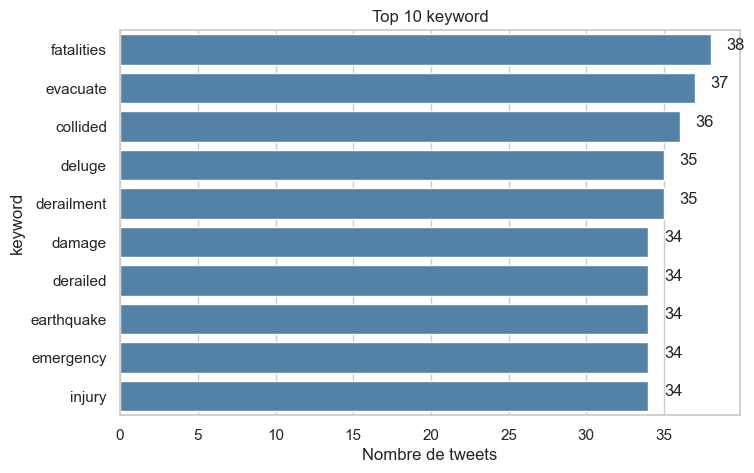

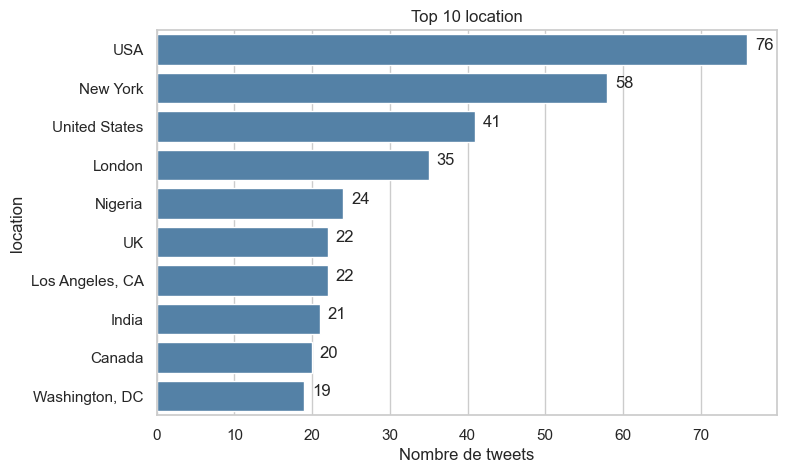

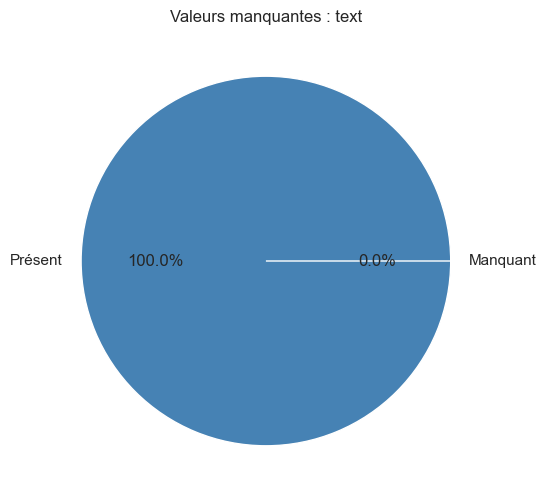

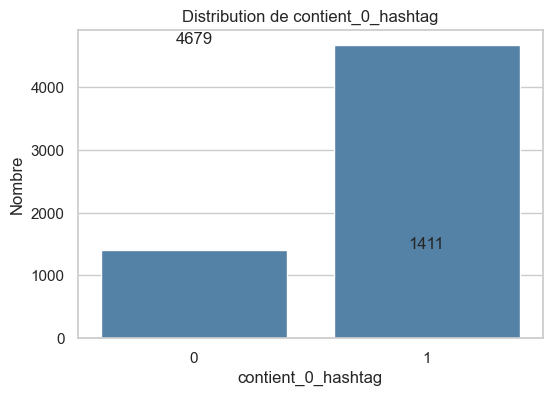

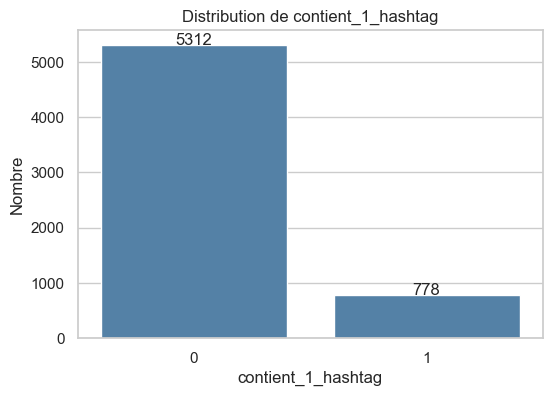

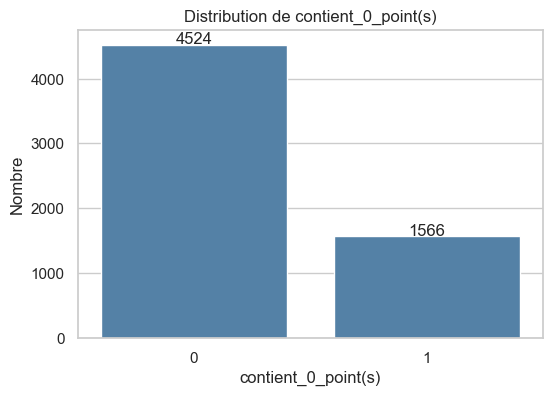

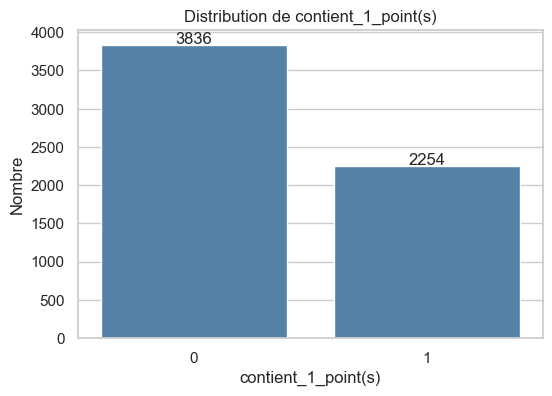

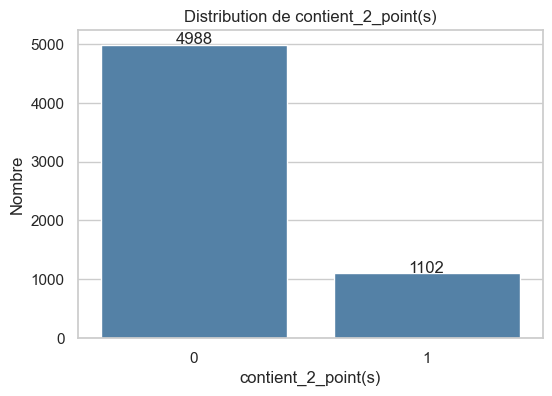

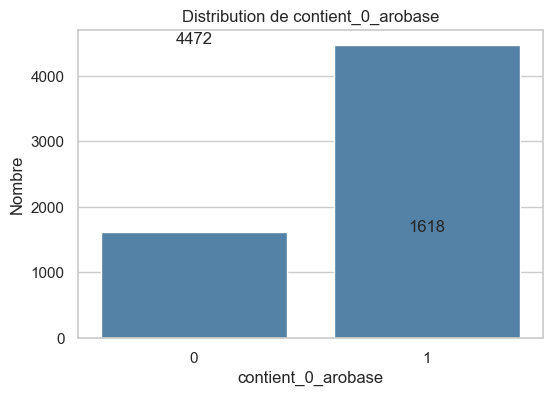

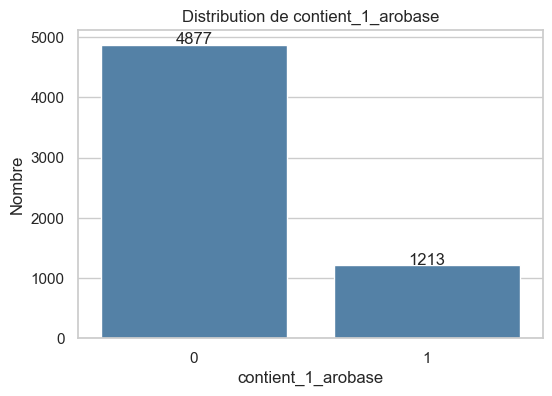

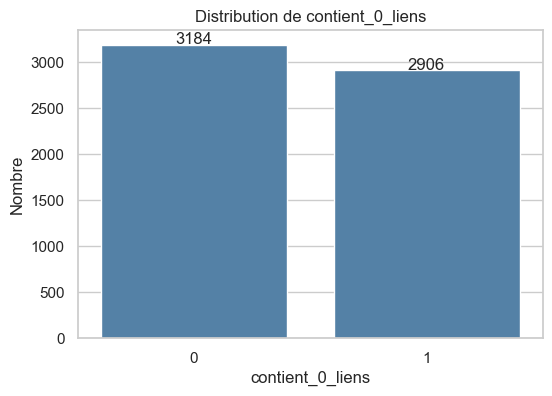

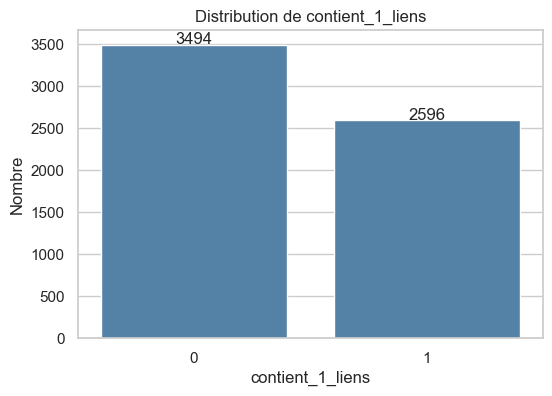

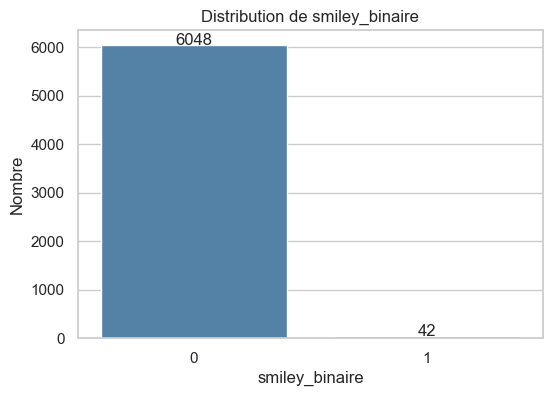

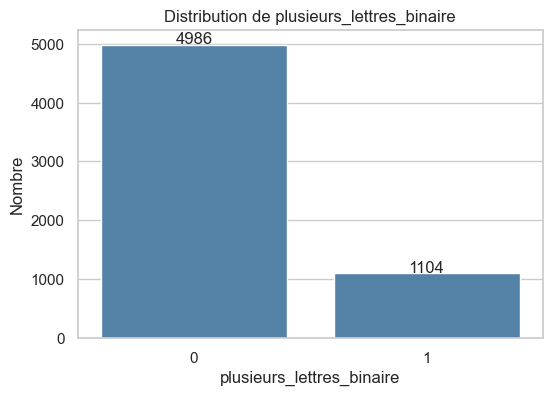

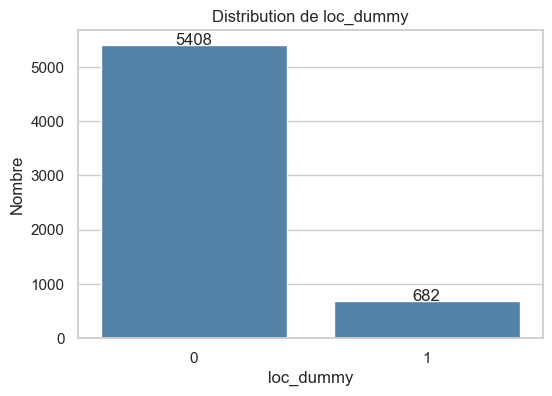

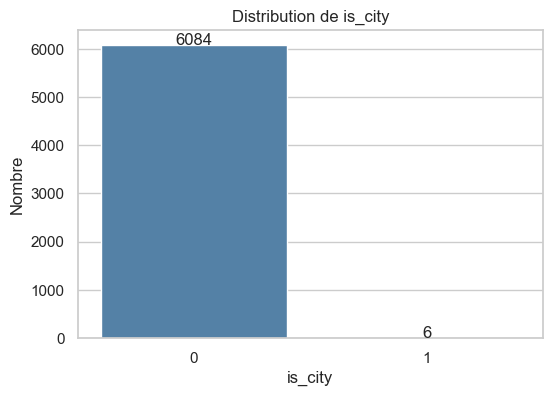

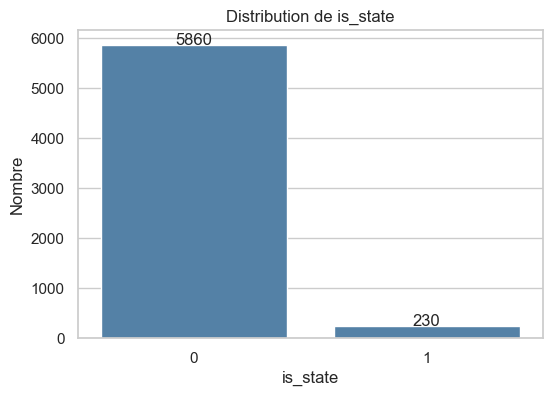

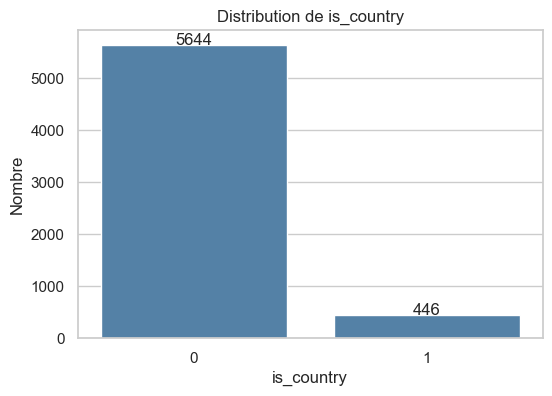

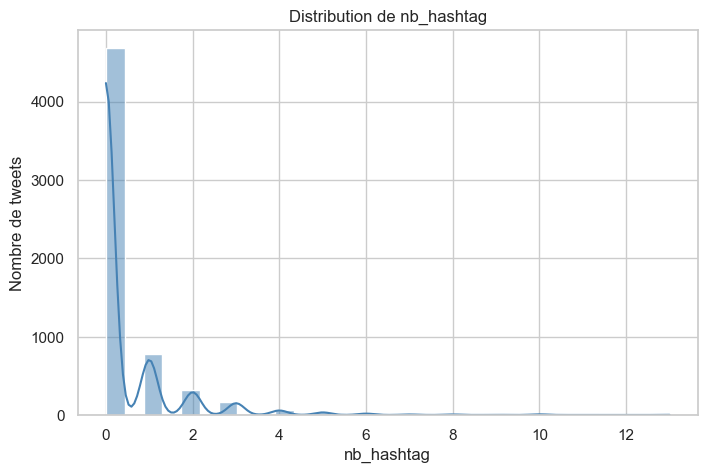

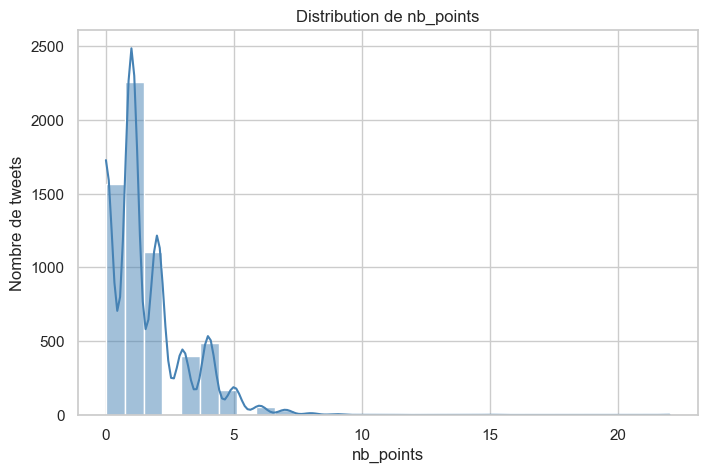

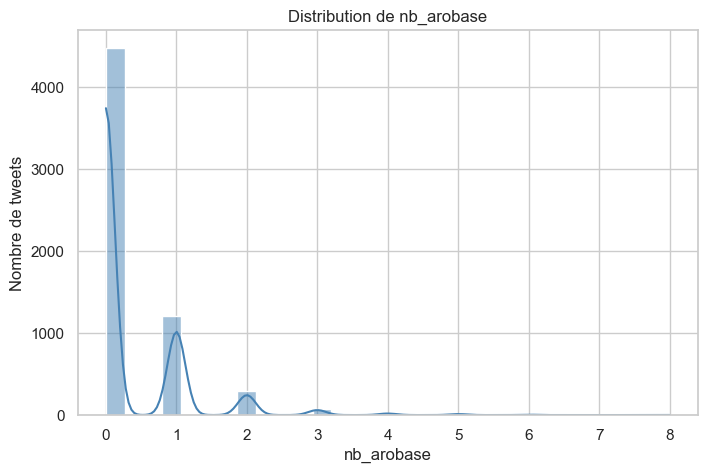

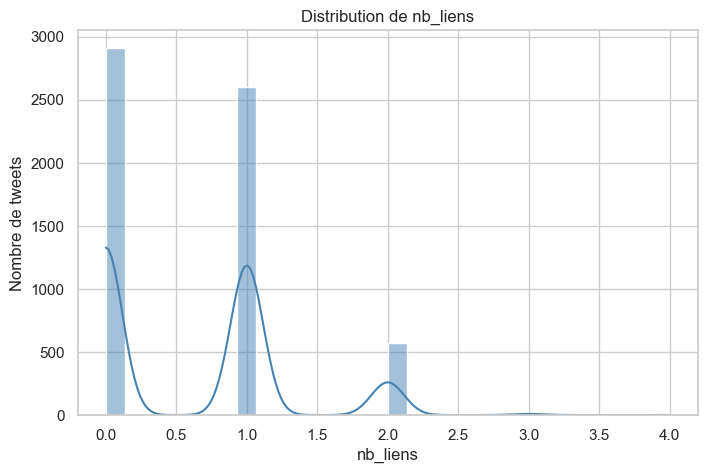

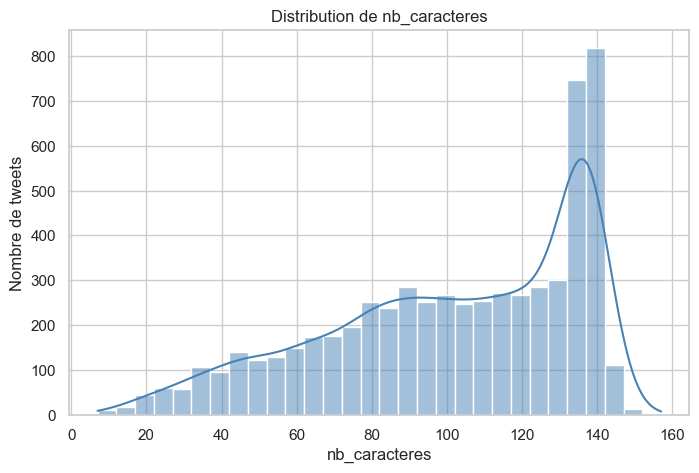

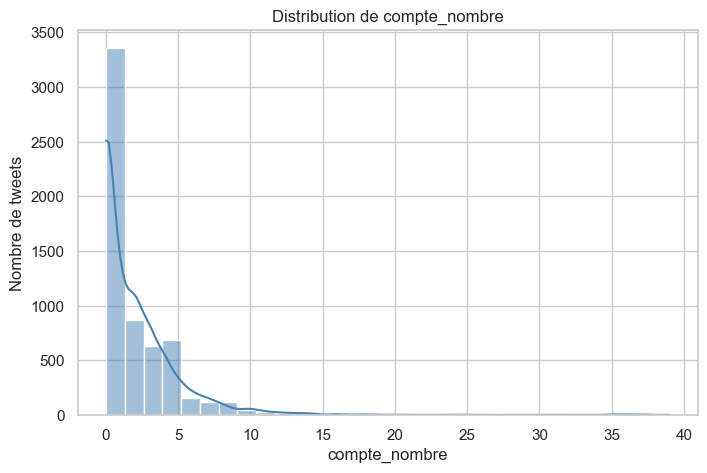

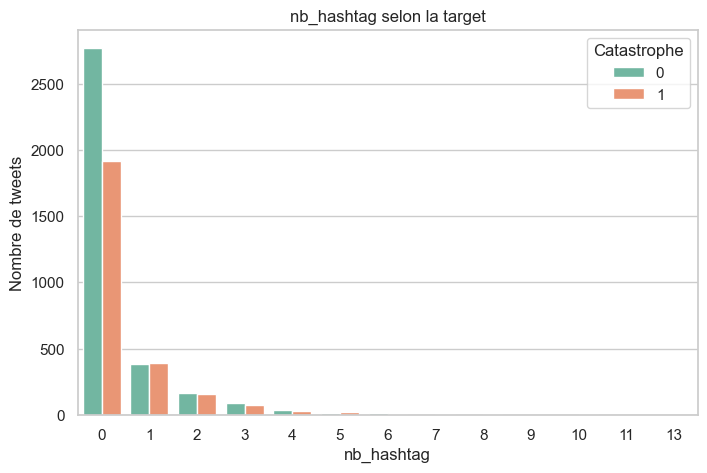

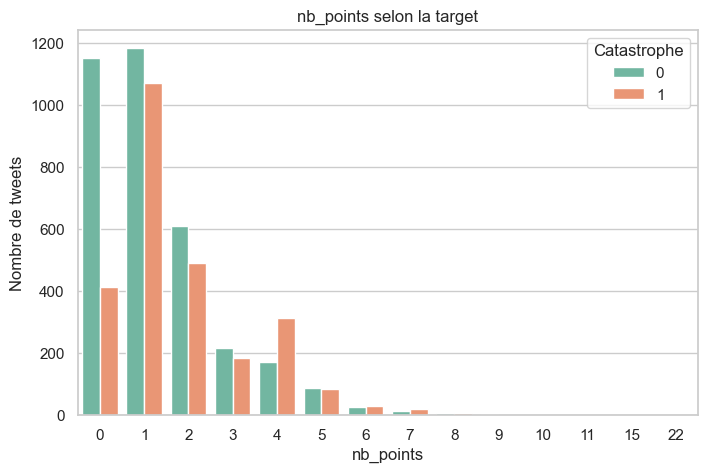

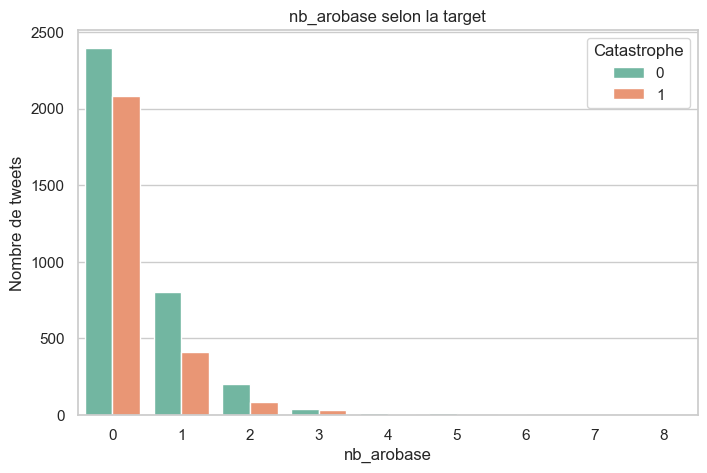

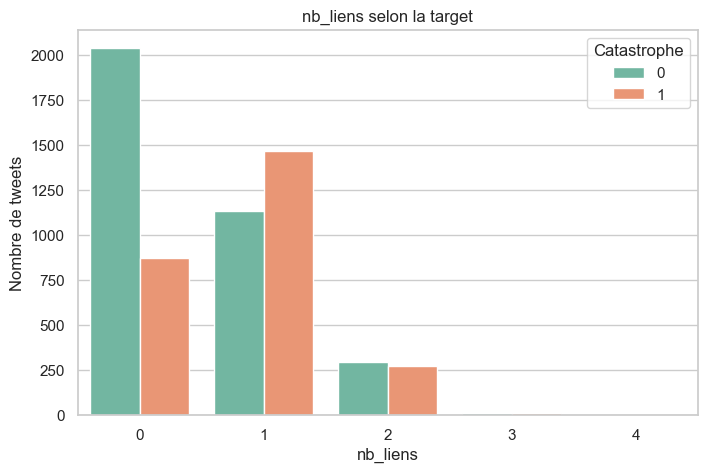

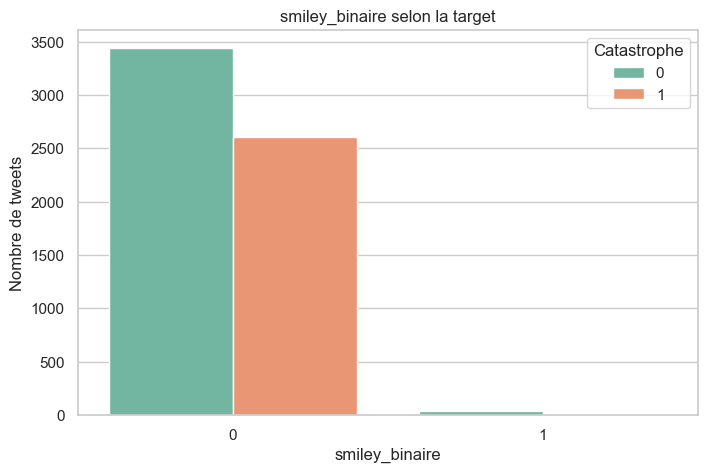

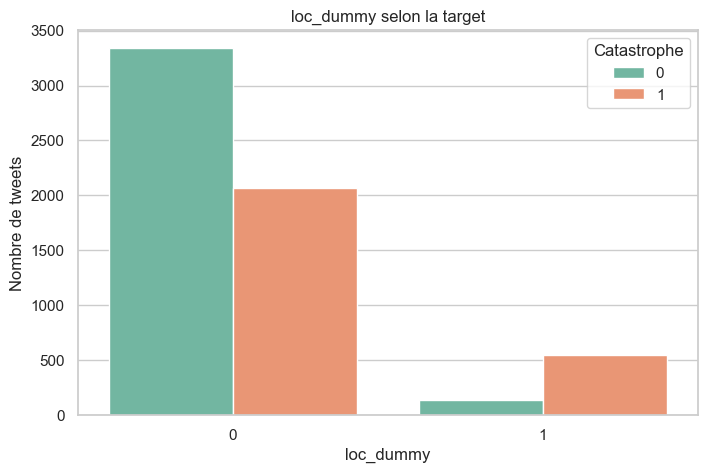

In [46]:
visualiseur = IndicatorVisualizer(df_train)
visualiseur.plot_all()

In [47]:
cols_to_keep = [
    'target',
    'loc_dummy',
    'nb_liens',
    'nb_caracteres',
    'compte_nombre',
    'nb_points',
    'is_state',
    'text',
    'contient_1_liens',
    'plusieurs_lettres_binaire'
]

# Piste non retenue : df_train2 = df_train[cols_to_keep]
# Le tableau exploratoire contient des regroupements dependants du corpus.
# On reconstruit les variables retenues depuis le brut avec le code d'inference.
features_finales = appliquer_feature_engineering(df_exploration_brut)
df_train2 = features_finales[cols_to_keep].copy()
assert set(df_train2.select_dtypes(include="number").columns) == set(COLS_NUMERIQUES) | {"target"}
assert features_finales["id"].equals(df_exploration_brut["id"])
assert not set(features_finales["id"]) & ids_holdout_reserves
assert df_train2.index.equals(df_exploration_brut.index)
assert_frame_equal(
    appliquer_feature_engineering(df_exploration_brut.iloc[[0]]),
    features_finales.iloc[[0]],
)
display(df_train2.head())

,target,loc_dummy,nb_liens,nb_caracteres,compte_nombre,nb_points,is_state,text,contient_1_liens,plusieurs_lettres_binaire
0,1,0,0,69,0,0,0,our deeds are the reason of this #earthquake may allah forgive us all,0,0
1,1,1,0,38,0,1,0,forest fire near la ronge sask. canada,0,0
2,1,0,0,133,0,1,0,all residents asked to 'shelter in place' are being notified by officers. no other evacuation or shelter in place orders are expected,0,0
3,1,1,0,65,5,0,1,"13,000 people receive #wildfires evacuation orders in california",0,0
4,1,1,0,88,0,0,0,just got sent this photo from ruby #alaska as smoke from #wildfires pours into a school,0,0


### Bilan du feature engineering : ce qui est retenu et ce qui reste exploratoire

| Piste | Statut final | Raison / reserve |
|---|---|---|
| Longueur du tweet | Retenue, compte brut | Definition fixe ; pas de seuil appris sur tout le corpus |
| Liens HTTP/HTTPS et exactement un lien | Retenus | Compteurs fixes, independants du lot |
| Chiffres et points | Retenus | Compteurs fixes ; dernier caractere maintenant inclus |
| Trois caracteres repetes hors chiffres | Retenue | Heuristique large : lettres **et** ponctuation |
| Presence d'un lieu / d'un Etat US | Retenue | Recherche dans le texte, lexiques limites et ambigus |
| Dummies rares hashtags/arobases/chiffres | Exploratoires | Definitions dependantes des frequences du corpus |
| Quartiles de longueur | Exploratoires | Seuils descriptifs ; redondance possible avec la longueur |
| Smileys, dates, mots catastrophe | Exploratoires | Essais conserves ; apport non demontre |
| Continents et premieres recherches de pays | Non retenus | Couverture partielle / methodes incorrectes commentees |
| `keyword`, `location` du CSV | Non utilises | Choix de representation : travailler sur le contenu du tweet |

**On ne pretend pas avoir prouve cette selection optimale.** Il manque une
ablation controlee (texte seul, puis ajout de groupes de variables) realisee
dans une CV sans fuite. Cette liste est un choix de representation, pas une selection optimale demontree.

Les dummies exploratoires ne sont pas « apprises » sur les tweets d'inference.
La reconstruction ci-dessus et la fonction d'entrainement utilisent toutes deux
`appliquer_feature_engineering`, egalement utilisee par le CLI et Flask.

In [48]:
# cols_to_drop = [
# 'id',
# 'city',
# '5_dates_text',
# '3_dates_text',
# 'is_city',
# 'contient_2_point(s)',
# 'contient_2_3_4_liens',
# 'contient_7_nombre',
# 'contient_8_nombre',
# 'contient_4_nombre',
# 'contient_6_nombre',
# '1_dates_text',
# '2_dates_text',
# '4_dates_text',
# 'contient_0_hashtag',
# 'contient_2_3_4_5_6_7_8_9_10_11_13_hashtags',
# 'bool_loc',
# 'is_country'
# ]

# df_train2 = df_train.drop(columns=cols_to_drop)

## Modelisation supervisee et protocole d'evaluation

La comparaison porte sur la regression logistique et la foret aleatoire,
avec TF-IDF et variables numeriques. Le clustering KMeans est une piste
non retenue ; aucun resultat de clustering n'est revendique.

**Protocole** : holdout groupe reserve des le chargement ; selection de la
famille et des hyperparametres par F1 moyen de CV groupee sur les seules
observations d'entrainement ; seuil fixe a 0,5 ; evaluation du seul modele
selectionne ; puis reajustement de sa configuration pour l'inference.

La classe ci-dessous reste en commentaire comme **piste non retenue** :
elle choisit la famille sur le meme holdout que celui utilise pour annoncer
le score et ne regroupe pas les doublons. Ses predictions sur tout le corpus
melangent aussi observations vues et non vues au fit et ne sont pas une
evaluation. La fonction partagee garantit le protocole defini ci-dessus,
avec une grille finie et les graines fixees.

In [49]:
corr = df_train.corr(numeric_only=True)
correlations_target = corr["target"].drop("target").sort_values(ascending=False)
display(correlations_target.rename("correlation_avec_target").to_frame())

,correlation_avec_target
loc_dummy,0.267096
contient_1_liens,0.234384
is_country,0.206700
nb_liens,0.203563
nb_caracteres,0.178656
compte_nombre,0.173019
is_state,0.155146
nb_points,0.154493
nb_caracteres_Q4,0.120692
contient_0_arobase,0.118119


**Attention aux correlations** : il s'agit d'une description univariee du
corpus, pas d'un classement d'importance du modele. Une association lineaire
faible n'exclut pas un signal non lineaire ; une forte association peut etre
redondante avec d'autres variables. Aucune variable supplementaire n'est choisie
en fonction du score du holdout final.

In [50]:
# PISTE NON RETENUE, NON EXECUTEE
# Non retenue car cette classe selectionne la famille sur le holdout, sans groupes de doublons.
# class TextPreprocessorBuilder:
#     
#     def __init__(self, text_column, numeric_columns=None, max_features=5000):
#         self.text_column = text_column
#         self.numeric_columns = list(numeric_columns) if numeric_columns else []
#         self.max_features = max_features
#         self.preprocessor = None
#
#     def build(self):
#         
#         tfidf = TfidfVectorizer(
#             max_features=self.max_features,
#             stop_words='english'
#         )
#         text_cols = self.text_column if isinstance(self.text_column, str) else list(self.text_column)
#
#         if self.numeric_columns:
#             self.preprocessor = ColumnTransformer(
#                 transformers=[
#                     ('tfidf', tfidf, text_cols),
#                     ('num', StandardScaler(), self.numeric_columns)
#                 ],
#                 remainder='drop'
#             )
#         else:
#             self.preprocessor = ColumnTransformer(
#                 transformers=[
#                     ('tfidf', tfidf, text_cols)
#                 ],
#                 remainder='drop'
#             )
#
#         return self.preprocessor
#
# class SupervisedModelTrainer:
#     
#     def __init__(self, data, target_column, preprocessor, models_param, random_state=42):
#         self.data = data
#         self.target_column = target_column
#         self.preprocessor = preprocessor
#         self.models_param = models_param
#         self.random_state = random_state
#         
#         self.results = []
#         self.best_estimators = {}
#         self.best_model = None
#     
#     def split_data(self, test_size=0.2):
#         self.train_df, self.test_df = train_test_split(
#             self.data,
#             test_size=test_size,
#             random_state=self.random_state,
#             stratify=self.data[self.target_column]
#         )
#
#         self.y_train = self.train_df[self.target_column].values
#         self.y_test = self.test_df[self.target_column].values
#     
#     def train_models(self, n_iter=20, scoring='f1'):
#         
#         cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=self.random_state)
#
#         for name, (estimator, param_dist) in self.models_param.items():
#
#             print(f"\n=== Training {name} ===")
#
#             pipe = Pipeline([
#                 ('pre', self.preprocessor),
#                 ('clf', estimator)
#             ])
#
#             rs = RandomizedSearchCV(
#                 estimator=pipe,
#                 param_distributions=param_dist,
#                 n_iter=n_iter,
#                 cv=cv,
#                 scoring=scoring,
#                 n_jobs=-1,
#                 random_state=self.random_state,
#                 verbose=1
#             )
#
#             rs.fit(self.train_df, self.y_train)
#
#             best = rs.best_estimator_
#             self.best_estimators[name] = best
#
#             y_pred = best.predict(self.test_df)
#             y_proba = best.predict_proba(self.test_df)[:,1] if hasattr(best, 'predict_proba') else None
#
#             metrics = self.evaluate(y_pred, y_proba)
#
#             print(f"Best params ({name}): {rs.best_params_}")
#             print(metrics)
#
#             self.results.append({
#                 'model': name,
#                 'best_params': rs.best_params_,
#                 **metrics
#             })
#
#         return self
#     
#     def evaluate(self, y_pred, y_proba=None):
#
#         m_accuracy = accuracy_score(self.y_test, y_pred)
#         m_precision = precision_score(self.y_test, y_pred, zero_division=0)
#         m_recall = recall_score(self.y_test, y_pred, zero_division=0)
#         m_f1 = f1_score(self.y_test, y_pred, zero_division=0)
#         m_roc = roc_auc_score(self.y_test, y_proba) if y_proba is not None else None
#
#         return {
#             'accuracy': m_accuracy,
#             'precision': m_precision,
#             'recall': m_recall,
#             'f1': m_f1,
#             'roc_auc': m_roc
#         }
#     
#     def select_best_model(self):
#
#         res_df = pd.DataFrame(self.results).sort_values('f1', ascending=False)
#         print("\nRésumé des modèles triés par F1:")
#         print(res_df)
#
#         if not res_df.empty:
#             best_name = res_df.iloc[0]['model']
#             self.best_model = self.best_estimators[best_name]
#             print(f"\nMeilleur modèle sélectionné: {best_name}")
#
#         return self.best_model
#     
#     def predict_full_dataset(self):
#
#         if self.best_model is None:
#             raise RuntimeError("Aucun modèle sélectionné.")
#
#         self.data['pred_best'] = self.best_model.predict(self.data)
#
#         if hasattr(self.best_model, 'predict_proba'):
#             self.data['pred_best_proba'] = self.best_model.predict_proba(self.data)[:,1]
#
#         return self.data
#
# numeric_cols = [c for c in df_train2.select_dtypes(include='number').columns
#                 if c not in ('target')]
#
# models_param = {
#     'logistic_regression': (
#         LogisticRegression(max_iter=1000, solver='liblinear'),
#         {
#             'clf__C': uniform(0.01, 10),
#             'clf__penalty': ['l1', 'l2']
#         }
#     ),
#     'random_forest': (
#         RandomForestClassifier(),
#         {
#             'clf__n_estimators': randint(50, 200),
#             'clf__max_depth': randint(3, 20),
#             'clf__min_samples_split': randint(2, 10)
#         }
#     )
# }
#
# builder = TextPreprocessorBuilder(
#     text_column='text',
#     numeric_columns=numeric_cols
# )
#
# preprocessor = builder.build()
#
# trainer = SupervisedModelTrainer(
#     data=df_train2,
#     target_column='target',
#     preprocessor=preprocessor,
#     models_param=models_param
# )
#
# trainer.split_data()
# trainer.train_models()
# best_model = trainer.select_best_model()
#
# df_train2 = trainer.predict_full_dataset()

# PROTOCOLE D'EVALUATION : separation identique a celle reservee au chargement.
report = entrainer(
    DATA_DIR / "train.csv",
    dossier_modeles=Path("projet_nlp") / "models",
    dossier_rapport=Path("reports"),
)
display(pd.DataFrame(report["cv"]).T)
print("Modele selectionne uniquement par CV :", report["selected_model"])
print("Groupes communs entrainement / holdout :", report["data"]["overlapping_groups"])
assert report["data"]["overlapping_groups"] == 0
assert report["data"]["n_train"] == len(df_exploration_brut)
assert report["data"]["n_holdout"] == len(ids_holdout_reserves)
ids_rapport = pd.read_csv(Path("reports") / "holdout_predictions.csv", usecols=["id"])["id"]
assert ids_rapport.tolist() == df_train_brut.iloc[indices_holdout]["id"].tolist()


[Chargement] projet_nlp\data\train.csv → 7613 lignes, 5 colonnes.


[Entrainement] logistic_regression


[Entrainement] random_forest


{
  "accuracy": 0.8003939592908733,
  "precision": 0.7777777777777778,
  "recall": 0.7492354740061162,
  "f1": 0.7632398753894081,
  "roc_auc": 0.8616128771163029,
  "average_precision": 0.8617904982559648,
  "brier": 0.14932220124014908
}


,mean_f1,std_f1,best_params
logistic_regression,0.740442,0.016187,"{'clf__C': 1.0, 'clf__class_weight': 'balanced'}"
random_forest,0.688138,0.007476,"{'clf__class_weight': 'balanced', 'clf__max_depth': None}"


Modele selectionne uniquement par CV : logistic_regression
Groupes communs entrainement / holdout : 0


### Interpretation et limites du protocole

Le TF-IDF (5 000 termes, stop words anglais) et le StandardScaler sont ajustes
dans les plis, pas sur tout le corpus avant CV. La suppression de stop words
peut enlever des indices de negation : c'est une limite de cette representation.
Un modele de langage peut faire l'objet d'une comparaison ulterieure, sans
presumer de meilleures performances.

Les groupes et les indices sont ceux reserves au chargement. Les copies
normalisees ne traversent pas les plis ; des quasi-doublons ou tweets d'un
meme evenement peuvent cependant rester des deux cotes. Les groupes a
etiquettes contradictoires sont signales, sans relabellisation arbitraire.

**Ne pas retoucher variables ou seuil a partir des resultats du holdout.**
Ce corpus a deja servi a des choix exploratoires : la separation precoce
structure l'execution, mais ne constitue pas de nouvelles donnees independantes.
Toute nouvelle decision inspiree du holdout demande une autre evaluation.

## Sauvegarde du modele et tracabilite

La sauvegarde se fait dans `projet_nlp/models`, dossier utilise par l'inference.
La configuration selectionnee par CV est reajustee sur toutes les observations
etiquetees **apres l'evaluation du holdout**. Les metriques publiees sont celles
du modele evalue avant ce reajustement, pas une mesure sur les donnees du fit final.

La sauvegarde commentee ci-dessous est une piste non retenue : son chemin
`models` a la racine differe du dossier d'inference et elle conserve le modele
ajuste uniquement sur la partie entrainement.

Les fichiers joblib sont locaux et exclus de Git. Ne charger que des fichiers
de confiance : la deserialisation peut executer du code.

In [51]:
# PISTE NON RETENUE, NON EXECUTEE
# Non retenue car le chemin differe de l'inference et le fit ne couvre pas toutes les lignes ; entrainer gere les artefacts.
# import joblib
# import os
# from datetime import datetime
#
# # -------------------------------------------------------
# # Répertoire de sauvegarde
# # -------------------------------------------------------
# MODELS_DIR = os.path.join(os.getcwd(), "models")
# os.makedirs(MODELS_DIR, exist_ok=True)
#
# # -------------------------------------------------------
# # 1. Colonnes utilisées pour l'entraînement
# #    (liste fixe définie par cols_to_keep, sans 'target')
# # -------------------------------------------------------
# cols_modele = [c for c in cols_to_keep if c != 'target']
#
# cols_path = os.path.join(MODELS_DIR, "colonnes_numeriques.joblib")
# joblib.dump(
#     [c for c in cols_modele if c != 'text'],  # uniquement les colonnes numériques
#     cols_path
# )
# print(f"✅ Colonnes numériques sauvegardées → {cols_path}")
#
# # -------------------------------------------------------
# # 2. Meilleur modèle (pipeline complète)
# # -------------------------------------------------------
# modele_path = os.path.join(MODELS_DIR, "best_model.joblib")
# joblib.dump(best_model, modele_path)
# print(f"✅ Meilleur modèle sauvegardé      → {modele_path}")
#
# # -------------------------------------------------------
# # 3. Tous les estimateurs entraînés
# # -------------------------------------------------------
# for nom, estimateur in trainer.best_estimators.items():
#     chemin = os.path.join(MODELS_DIR, f"{nom}.joblib")
#     joblib.dump(estimateur, chemin)
#     print(f"   → {nom} sauvegardé : {chemin}")
#
# # -------------------------------------------------------
# # 4. Métadonnées d'entraînement
# # -------------------------------------------------------
# resultats_df = pd.DataFrame(trainer.results)
# metadonnees = {
#     "date_entrainement": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
#     "meilleur_modele": resultats_df.sort_values('f1', ascending=False).iloc[0]['model'],
#     "colonnes_modele": cols_modele,
#     "colonnes_numeriques": [c for c in cols_modele if c != 'text'],
#     "colonne_texte": "text",
#     "colonne_cible": "target",
#     "resultats": resultats_df.to_dict(orient="records")
# }
# metadonnees_path = os.path.join(MODELS_DIR, "metadonnees_entrainement.joblib")
# joblib.dump(metadonnees, metadonnees_path)
# print(f"✅ Métadonnées sauvegardées         → {metadonnees_path}")
#
# print("\n--- Résumé des performances ---")
# print(resultats_df.sort_values('f1', ascending=False).to_string(index=False))

MODELS_DIR = Path("projet_nlp") / "models"
REPORTS_DIR = Path("reports")
assert (MODELS_DIR / "best_model.joblib").is_file()
assert (MODELS_DIR / "colonnes_numeriques.joblib").is_file()
rapport_disque = json.loads((REPORTS_DIR / "evaluation.json").read_text(encoding="utf-8"))
assert rapport_disque == report
display(pd.Series(report["versions"], name="versions_utilisees").to_frame())
print("Empreinte SHA-256 du CSV :", report["dataset_sha256"])

,versions_utilisees
python,3.12.10
scikit_learn,1.9.0
pandas,3.0.3
numpy,2.4.6
joblib,1.5.3


Empreinte SHA-256 du CSV : 61111c6dc31eaffa34d1e1fa62e2395325c9bc3b38bba1941a5f1ed9b3fa60df


In [52]:
df_train['nb_liens'].dtype

dtype('int64')

In [53]:
df_train.head()

,id,keyword,location,text,target,nb_hashtag,contient_0_hashtag,contient_1_hashtag,contient_2_3_4_5_6_7_8_9_10_11_13_hashtags,nb_points,...,4_dates_text,5_dates_text,plus_de_5_dates_text,text_clean,location_found,location_type,loc_dummy,is_city,is_state,is_country
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake May ALLAH Forgive us all,1,1,0,1,0,0,...,0,0,0,our deeds are the reason of this #earthquake may allah forgive us all,NaN,NaN,0,0,0,0
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1,0,1,0,0,1,...,0,0,0,forest fire near la ronge sask. canada,la ronge,city,1,1,0,0
2,5,NaN,NaN,All residents asked to 'shelter in place' are being notified by officers. No other evacuation or shelter in place orders are expected,1,0,1,0,0,1,...,0,0,0,all residents asked to 'shelter in place' are being notified by officers. no other evacuation or shelter in place orders are expected,NaN,NaN,0,0,0,0
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation orders in California",1,1,0,1,0,0,...,0,0,0,"13,000 people receive #wildfires evacuation orders in california",california,state,1,0,1,0
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as smoke from #wildfires pours into a school,1,2,0,0,1,0,...,0,0,0,just got sent this photo from ruby #alaska as smoke from #wildfires pours into a school,ruby,city,1,1,0,0


## Evaluation hors entrainement : reference, metriques et incertitude

La **reference majoritaire** repond toujours la classe la plus frequente
apprise sur l'entrainement ; pour les probabilites, elle renvoie la proportion
de catastrophes de cet entrainement. Elle ne lit pas les tweets.

Le **F1** combine precision et rappel de la classe catastrophe. L'accuracy
seule peut masquer les catastrophes manquees. ROC-AUC et average precision
evaluent le classement des scores.

Le **Brier** est la moyenne de `(probabilite - cible)^2` : plus petit = mieux.
Une erreur tres assuree est davantage penalisee ; ce n'est pas un pourcentage
de classifications fausses, et il ne prouve pas seul une bonne calibration.

Les **IC a 95 %** du F1 et de l'accuracy sont des intervalles percentile obtenus
avec 2 000 tirages bootstrap de groupes de textes a modele fixe.
Ils ne sont pas des IC sur un tweet, et ne couvrent ni le reentrainement,
ni la selection du modele, ni le changement de distribution. Un IC de Wilson
applique a une probabilite individuelle avec `n=1` n'est pas utilise.

,modele_selectionne,reference_majoritaire
accuracy,0.8004,0.5706
precision,0.7778,0.0000
recall,0.7492,0.0000
f1,0.7632,0.0000
roc_auc,0.8616,0.5000
average_precision,0.8618,0.4294
brier,0.1493,0.2450


,lower,upper,confidence,n_bootstrap,method
accuracy,0.780051,0.820771,0.95,2000,percentile_group_bootstrap_fixed_model
f1,0.735893,0.790015,0.95,2000,percentile_group_bootstrap_fixed_model


,audit_donnees
n_total,7613
n_train,6090
n_holdout,1523
class_counts,"{'0': 4342, '1': 3271}"
duplicate_normalized_texts,112
conflicting_label_groups,18
overlapping_groups,0


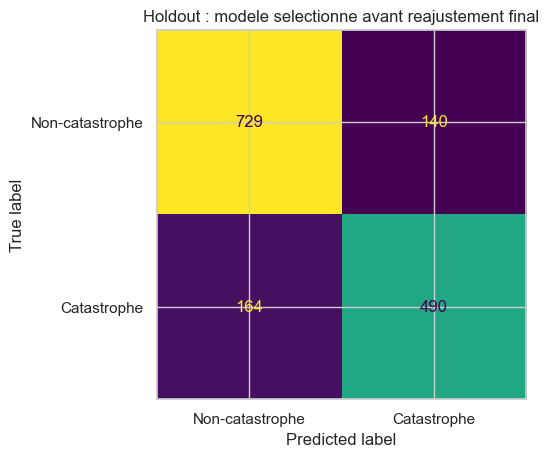

In [54]:
comparaison = pd.DataFrame({
    "modele_selectionne": report["holdout_metrics"],
    "reference_majoritaire": report["baseline"]["metrics"],
})
display(comparaison.round(4))
display(pd.DataFrame(report["holdout_intervals"]).T)
display(pd.Series(report["data"], name="audit_donnees").to_frame())

# Verification des plis reserves des le chargement, sans nouvelle separation.
for fit_pli, validation_pli in plis_cv:
    assert not set(groupes_evaluation.iloc[indices_fit[fit_pli]]) & set(groupes_evaluation.iloc[indices_fit[validation_pli]])
holdout = pd.read_csv(REPORTS_DIR / "holdout_predictions.csv")
assert holdout["id"].tolist() == df_train_brut.iloc[indices_holdout]["id"].tolist()
assert set(holdout["id"]) == ids_holdout_reserves
assert len(holdout) == report["data"]["n_holdout"]
assert holdout["id"].is_unique
ConfusionMatrixDisplay.from_predictions(
    holdout["target"], holdout["prediction"],
    display_labels=["Non-catastrophe", "Catastrophe"], colorbar=False,
)
plt.title("Holdout : modele selectionne avant reajustement final")
plt.show()

### Probabilites : une verification descriptive de la calibration

Une probabilite de 0,8 devrait correspondre a environ 80 % de positifs parmi
des observations comparables si le modele est calibre. La courbe suivante
regroupe des scores ; elle est descriptive et sensible aux effectifs.
`class_weight='balanced'` peut aider le F1 sans garantir des probabilites
calibrees. Aucune recalibration n'est ajustee sur ce holdout.

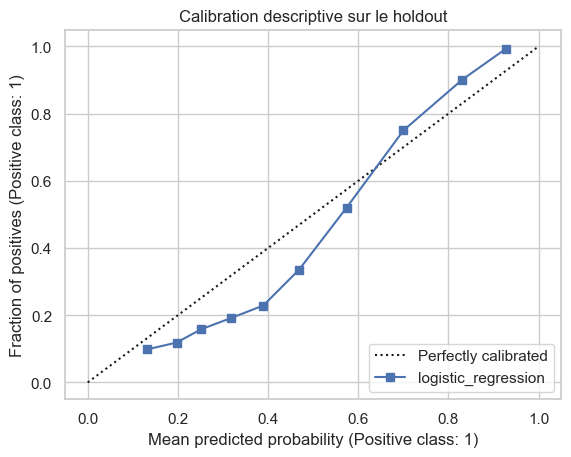

In [55]:
CalibrationDisplay.from_predictions(
    holdout["target"], holdout["probability"],
    n_bins=10, strategy="quantile", name=report["selected_model"],
)
plt.title("Calibration descriptive sur le holdout")
plt.show()

### Examiner les erreurs sans reutiliser le holdout pour optimiser

Faux positifs : tweets classes catastrophe alors que l'annotation vaut 0.
Faux negatifs : catastrophes annotees que le modele manque.
Les exemples les plus assures ci-dessous ne sont pas representatifs et
l'annotation peut elle-meme etre discutable. Nous ne les relabellisons pas.
Toute nouvelle idee inspiree de ces exemples devra etre testee ailleurs.

In [56]:
erreurs = holdout.loc[holdout["target"] != holdout["prediction"]].merge(
    df_train_brut[["id", "text"]], on="id", validate="one_to_one",
)
print("Faux positifs les plus assures :")
display(erreurs.loc[erreurs["prediction"] == 1].nlargest(5, "probability"))
print("Faux negatifs les plus assures :")
display(erreurs.loc[erreurs["prediction"] == 0].nsmallest(5, "probability"))

Faux positifs les plus assures :


,id,target,prediction,probability,text
111,3989,0,1,0.942972,Fascinating pics from inside North Korea. Not propaganda not devastation - just people living life. http://t.co/E2Dbcpwd9u
46,1707,0,1,0.871388,Ashes 2015: AustraliaÛªs collapse at Trent Bridge among worst in history: England bundled out Australia for 60 ... http://t.co/t5TrhjUAU0
207,7196,0,1,0.834718,'Up to 40% of businesses affected by a natural or man-made disaster never reopen'\nhttp://t.co/35JyAp0ul9
60,2108,0,1,0.823982,.@stavernise: France agreed to repay Russia for two warships which were never delivered after economic sanctions http://t.co/K4H8cq7puo
227,8017,0,1,0.809282,Newlyweds feed Syrian refugees at their wedding - CBC News - Latest Canada World Entertainment and Business News http://t.co/QU8S89pVVt


Faux negatifs les plus assures :


,id,target,prediction,probability,text
99,3607,1,0,0.072423,Just came back from camping and returned with a new song which gets recorded tomorrow. Can't wait! #Desolation #TheConspiracyTheory #NewEP
101,3640,1,0,0.076484,This desperation dislocation\nSeparation condemnation\nRevelation in temptation\nIsolation desolation\nLet it go and so to find away
243,8528,1,0,0.085142,#NoChillLukeHammings\nIM SCREAMING
273,9791,1,0,0.088549,@BoyInAHorsemask its a panda trapped in a dogs body
174,6120,1,0,0.112356,@gg_keeponrockin @StrawberrySoryu Oh okay I just got the message twice and got suspicious. Sorry. I'll check it out!


## Conclusion du parcours exploratoire

L'exploration a produit des hypotheses de variables, des essais qui ne
fonctionnaient pas et une premiere comparaison de modeles. Les cellules
conservees montrent ce cheminement, sans presenter les essais abandonnes comme
des resultats valides. Les definitions des variables couvrent chiffres, dates,
quartiles, liens HTTP/HTTPS et recherche de lieux.

La pipeline partagee rend les transformations reproductibles et
l'evaluation plus rigoureuse. **Elle ne prouve pas que toutes les variables
manuelles soient utiles** : une ablation reste a faire. Les dictionnaires
geographiques sont restreints ; les emplois figures, negations et evenements
nouveaux restent difficiles.

Ce corpus est historique et anglophone. Les annotations parfois contradictoires,
les quasi-doublons et la dependance entre tweets d'un meme evenement limitent
les conclusions. Il n'y a ni score Kaggle externe verifie ni validation
temporelle/geographique. Ce projet est pedagogique, pas un systeme d'alerte.

Prochaines etapes possibles : ablation predefinie, nouvelles donnees
independantes, separation par evenement/date, revue d'annotations et
calibration sur un jeu dedie.